In [1]:
import random
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import deque

In [2]:
#create the map
ship = np.array([
    [0, 0, 0, 0, 0],
    [0, 1, 1, 0, 0],
    [0, 0, 0, 0, 1],
    [0, 1, 0, 0, 0],
    [0, 0, 0, 0, 0]
])

print(ship)

[[0 0 0 0 0]
 [0 1 1 0 0]
 [0 0 0 0 1]
 [0 1 0 0 0]
 [0 0 0 0 0]]


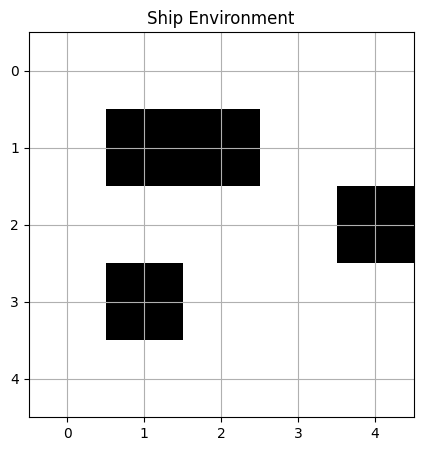

In [3]:
#draw the map
plt.figure(figsize=(5, 5))
plt.imshow(ship, cmap="Greys")

plt.xticks(range(5))
plt.yticks(range(5))
plt.grid()

plt.title("Ship Environment")
plt.show()

In [4]:
def bfs(ship, start, goal):
#define the function and the ship map, start and goal

    queue = deque([start])
    visited = {start}
    parent = {start: None}#record the previous step

    directions = [
        (-1, 0), (1, 0), (0, -1), (0, 1)]

#get the position
    while queue:

        current = queue.popleft()

        if current == goal:
            break

        row, col = current

        for dr, dc in directions:

            nr = row + dr
            nc = col + dc
            neighbor = (nr, nc)

            if (
                0 <= nr < ship.shape[0]
                and 0 <= nc < ship.shape[1]
                and ship[nr, nc] == 0
                and neighbor not in visited
            ):

                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)

    if goal not in visited:
        return None

    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()

    return path

In [5]:
#test the BFS
start = (0, 0)
goal = (4, 4)

path = bfs(ship, start, goal)

print("Shortest path:", path)

if path is not None:
    print("number of moves:", len(path) - 1)

Shortest path: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]
number of moves: 8


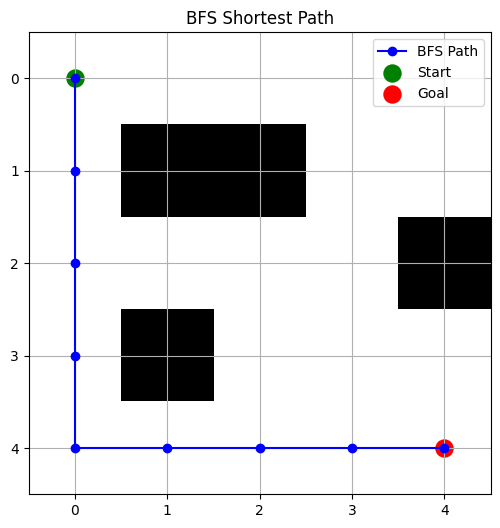

In [6]:
#plt
plt.figure(figsize=(6, 6))
plt.imshow(ship, cmap="Greys")

if path is not None:
    rows = [p[0] for p in path]
    cols = [p[1] for p in path]

    plt.plot(cols, rows, "b-o", label="BFS Path")

plt.scatter(start[1], start[0],
            color="green", s=150, label="Start")

plt.scatter(goal[1], goal[0],
            color="red", s=150, label="Goal")

plt.xticks(range(ship.shape[1]))
plt.yticks(range(ship.shape[0]))
plt.grid()

plt.title("BFS Shortest Path")
plt.legend()
plt.show()

In [8]:
#Type A detector
def detector_type_a(locator_pos, lost_pos, k):

    lr, lc = locator_pos
    br, bc = lost_pos
    #LocatorBot current position
    if locator_pos == lost_pos:
        return "FOUND"

    if abs(lr - br) <= k and abs(lc - bc) <= k:
        return "PING"

    return "NO PING"

locator_pos = (2, 2)
lost_pos = (3, 3)

print(detector_type_a(locator_pos, lost_pos, 1))
print(detector_type_a(locator_pos, lost_pos, 0))
print(detector_type_a(locator_pos, locator_pos, 1))

PING
NO PING
FOUND


In [9]:
possible_positions = set()

for r in range(ship.shape[0]):
    for c in range(ship.shape[1]):

        if ship[r, c] == 0:
            possible_positions.add((r, c))

print("Possible positions:", len(possible_positions))

Possible positions: 21


In [10]:
def update_knowledge_type_a(possible_positions, locator_pos, k, result):

    lr, lc = locator_pos

    detection_area = set()

    for r, c in possible_positions:
        if abs(r - lr) <= k and abs(c - lc) <= k:
            detection_area.add((r, c))

    if result == "PING":
        return possible_positions & detection_area

    elif result == "NO PING":
        return possible_positions - detection_area

    elif result == "FOUND":
        return {locator_pos}

    return possible_positions

In [12]:
#test knowledgebase update
locator_pos = (2, 2)
lost_pos = (3, 3)
k = 1

result = detector_type_a(locator_pos, lost_pos, k)

new_positions = update_knowledge_type_a(
    possible_positions,
    locator_pos,
    k,
    result
)

print("Detector result:", result)
print("Before update:", len(possible_positions))
print("After update:", len(new_positions))
print("Remaining positions:", sorted(new_positions))

Detector result: PING
Before update: 21
After update: 6
Remaining positions: [(1, 3), (2, 1), (2, 2), (2, 3), (3, 2), (3, 3)]


In [13]:
#realize baseline strategy
def find_nearest_position(ship, current_pos, possible_positions):

    nearest = None
    shortest_distance = float("inf")

    for pos in sorted(possible_positions):

        if pos == current_pos:
            continue

        path = bfs(ship, current_pos, pos)

        if path is None:
            continue

        distance = len(path) - 1

        if distance < shortest_distance:
            shortest_distance = distance
            nearest = pos

    return nearest

In [14]:
#test 
current_pos = (2, 2)

nearest = find_nearest_position(
    ship,
    current_pos,
    new_positions
)

print("Nearest possible position:", nearest)
print("Shortest path:", bfs(ship, current_pos, nearest))

Nearest possible position: (2, 1)
Shortest path: [(2, 2), (2, 1)]
